In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
from kagglehub import KaggleDatasetAdapter
from pathlib import Path

c:\Users\Daria\anaconda3\envs\ai-methods\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# --- Folders --------------------------------------------------------------
DATA_DIR = Path("../data")      # raw and clean CSV files go here
FIG_DIR = Path("../figures")    # exported plots go here
DATA_DIR.mkdir(exist_ok=True)  # create the folder if it does not exist yet
FIG_DIR.mkdir(exist_ok=True)

# --- pandas display options -------------------------------------------------
pd.set_option("display.max_columns", 50)                 # show every column, do not hide them with "..."
pd.set_option("display.float_format", "{:,.2f}".format)  # 1234567.891 -> 1,234,567.89

# --- plot style -------------------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")  # clean background with a light grid
plt.rcParams["figure.figsize"] = (10, 5)              # default size of every figure (width, height) in inches

# Seed for anything random (sampling): the same seed always gives the same "random" result,
# so everybody in class sees exactly the same numbers.
RANDOM_STATE = 42


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR.
    # dpi = dots per inch (resolution). bbox_inches="tight" trims empty white borders.
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

In [5]:
# Load our dataset from the repository (no download needed)
df = pd.read_csv(DATA_DIR / "anon2026_50k.csv")

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")

Loaded 50,000 rows and 96 columns


In [6]:
raw_path = DATA_DIR / "anon2026_50k.csv"

# Writing 100+ MB takes a few seconds, so we only do it the first time
if not raw_path.exists():
    df.to_csv(raw_path, index=False)  # index=False: do not write pandas' row numbers as an extra column
    print(f"Raw data saved to {raw_path}")
else:
    print(f"Raw data already saved in {raw_path}")

Raw data already saved in ..\data\anon2026_50k.csv


In [7]:
df.head()

,PROP_TYPE,PROP_AGE_BAND,FLOOR_AREA_BAND,CONSERVATORY_FLAG,COUNCIL_TAX_BAND,IMD_BAND_ENG,IMD_BAND_WALES,REGION,EPC,LI_FLAG,LI_DATE,CWI_FLAG,CWI_DATE,PV_FLAG,PV_DATE,MAIN_HEAT_FUEL,Gcons2024,Gcons2023,Gcons2022,Gcons2021,Gcons2020,Gcons2019,Gcons2018,Gcons2017,Gcons2016,...,Econs2009,Econs2008,Econs2007,Econs2006,Econs2005,ElecValFlag2024,ElecValFlag2023,ElecValFlag2022,ElecValFlag2021,ElecValFlag2020,ElecValFlag2019,ElecValFlag2018,ElecValFlag2017,ElecValFlag2016,ElecValFlag2015,ElecValFlag2014,ElecValFlag2013,ElecValFlag2012,ElecValFlag2011,ElecValFlag2010,ElecValFlag2009,ElecValFlag2008,ElecValFlag2007,ElecValFlag2006,ElecValFlag2005
0,Semi detached,3,2,NaN,A,3.00,NaN,E12000004,C,0,NaN,0,NaN,0,NaN,1,"6,600.00","6,600.00","5,500.00","6,600.00","7,400.00","7,400.00","9,600.00","9,600.00","6,700.00",...,"1,000.00",NaN,"1,600.00","2,300.00","2,200.00",V,V,V,V,V,V,V,L,V,V,V,V,V,V,V,V,L,V,V,V
1,Mid terrace,1,3,NaN,E,1.00,NaN,E12000007,No EPC,0,NaN,0,NaN,0,NaN,1,"13,500.00","14,100.00","12,500.00","13,900.00","16,900.00","17,000.00","15,100.00","16,500.00","17,400.00",...,"4,500.00","4,100.00","4,500.00","4,800.00","3,900.00",V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V
2,Detached,4,3,0.00,E,3.00,NaN,E12000005,A/B,0,NaN,0,NaN,0,NaN,1,"9,700.00","7,100.00","7,100.00","10,100.00",NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,V,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
3,Semi detached,4,2,0.00,C,4.00,NaN,E12000004,A/B,0,NaN,0,NaN,0,NaN,1,"5,700.00","5,200.00","5,300.00","5,300.00","10,500.00",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,V,V,V,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
4,Bungalow,2,2,NaN,D,5.00,NaN,E12000008,D,1,"2,006.00",0,NaN,0,NaN,1,"11,500.00","11,500.00","12,000.00","14,400.00","13,700.00","14,300.00","14,000.00","13,700.00","13,200.00",...,"3,500.00","3,800.00","3,300.00","3,700.00","3,900.00",V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 96 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   PROP_TYPE          50000 non-null  str    
 1   PROP_AGE_BAND      50000 non-null  int64  
 2   FLOOR_AREA_BAND    50000 non-null  int64  
 3   CONSERVATORY_FLAG  9539 non-null   float64
 4   COUNCIL_TAX_BAND   50000 non-null  str    
 5   IMD_BAND_ENG       47578 non-null  float64
 6   IMD_BAND_WALES     2422 non-null   float64
 7   REGION             50000 non-null  str    
 8   EPC                50000 non-null  str    
 9   LI_FLAG            50000 non-null  int64  
 10  LI_DATE            7180 non-null   float64
 11  CWI_FLAG           50000 non-null  int64  
 12  CWI_DATE           7164 non-null   float64
 13  PV_FLAG            50000 non-null  int64  
 14  PV_DATE            800 non-null    float64
 15  MAIN_HEAT_FUEL     50000 non-null  int64  
 16  Gcons2024          39502 non-null

**What do we notice already?**

- The table has **50,000 rows** (one row = one house in England or Wales) and **96 columns**.
- **52 columns are numeric** (`int64` / `float64`) and **44 columns are text** (`str`).
  The text columns are `PROP_TYPE`, `COUNCIL_TAX_BAND`, `REGION`, `EPC`, and the "validity flag" columns (for example `ElecValFlag2006`).
- Some numeric columns are really **codes**, not amounts. For example `PROP_AGE_BAND`, `FLOOR_AREA_BAND` and `MAIN_HEAT_FUEL`: each number means a category.
- Many columns have **missing values**, but not all of them are a problem:
  - `IMD_BAND_ENG` (47,578) + `IMD_BAND_WALES` (2,422) = 50,000. A house is in England **or** in Wales, so one of the two is always empty.
  - `LI_DATE`, `CWI_DATE` and `PV_DATE` are empty when nothing was installed. For example, only 800 houses have a solar panel date.
  - `CONSERVATORY_FLAG` has only 9,539 values. We need to check what an empty value means here.
  - The gas consumption columns (`Gcons2021`–`Gcons2024`) have about 39,000–39,500 values, so about 10,000 houses have no gas value.

In [9]:
# .T transposes the table (rows <-> columns) so it is easier to read with many columns
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PROP_TYPE,50000,6,Semi detached,12592,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PROP_AGE_BAND,"50,000.00",NaN,NaN,NaN,2.34,1.04,1.00,2.00,2.00,3.00,4.00
FLOOR_AREA_BAND,"50,000.00",NaN,NaN,NaN,2.29,0.91,1.00,2.00,2.00,3.00,5.00
CONSERVATORY_FLAG,"9,539.00",NaN,NaN,NaN,0.12,0.33,0.00,0.00,0.00,0.00,1.00
COUNCIL_TAX_BAND,50000,9,A,11539,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
ElecValFlag2009,49230,5,V,40793,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ElecValFlag2008,49230,5,V,40179,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ElecValFlag2007,49230,5,V,39781,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ElecValFlag2006,49230,5,V,39796,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### What does it tell us?

This table is a **statistical summary of every column**.

#### What each statistic means

**For text columns:**

| Statistic | Meaning |
|---|---|
| `count` | How many values are filled in (not missing) |
| `unique` | How many **different** values there are |
| `top` | The **most common** value |
| `freq` | How many times the most common value appears |

**For number columns:**

| Statistic | Meaning |
|---|---|
| `mean` | Average |
| `std` | How spread out the values are around the average |
| `min` / `max` | The smallest / largest value |
| `25%` / `50%` / `75%` | A quarter / half / three quarters of the houses are below this value. `50%` is the median |

**`NaN` in this table does not mean "missing data".** It means "this statistic does not fit this column".
We cannot calculate the average of "Semi detached", and there is no "most common value" for a number calculation.

#### What this tells us about our data

- **`PROP_TYPE`**: 50,000 houses and **6 different types**. The most common is **Semi detached**, with 12,592 houses (about a quarter).
- **`PROP_AGE_BAND`**: values go from **1 to 4**. This confirms it is a column of **codes** (four building-age groups).
  So **the mean of 2.34 has no meaning**: no house is in "age group 2.34".
  For code columns, what matters is how many houses are in each group, not the average.
- **`FLOOR_AREA_BAND`**: the same: codes from **1 to 5** (five floor-area groups).
- **`CONSERVATORY_FLAG`**: only 9,539 houses have a value. The values are **0 or 1** (no / yes conservatory).
  Here the mean of 0.12 **does** mean something: among the houses with a value, **about 12% have a conservatory**.
  Open question: do the ~40,000 empty values mean "no conservatory" or "unknown"?
- **`COUNCIL_TAX_BAND`**: **9 council tax bands**. The most common is **A** (the cheapest band), with 11,539 houses.
- **`ElecValFlag2005`–`2009`**: **5 different values**, and the most common is **V** (probably *Valid*, a correct meter reading).
  The earlier the year, the fewer V values: 40,793 in 2009, but only 35,273 in 2005.
  So **older data is less reliable**. This is a good reason to focus on the most recent years.


#  Data cleaning



In [10]:
# .copy() creates an independent copy: changing df_clean will NOT change df
df_clean = df.copy()

### 1.1 Tidy column names

Our column names already have no spaces or brackets (for example `PROP_TYPE`, `IMD_BAND_ENG`).
But they use capital letters, and names like `Gcons2024` mix words and years.
To keep all names in the same simple style (**snake_case**: lowercase words joined by `_`),
we change all 96 names in one step instead of writing them one by one.

In [11]:
# Make all column names lowercase (snake_case)
df_clean.columns = df_clean.columns.str.lower()
df_clean.columns.tolist()

['prop_type',
 'prop_age_band',
 'floor_area_band',
 'conservatory_flag',
 'council_tax_band',
 'imd_band_eng',
 'imd_band_wales',
 'region',
 'epc',
 'li_flag',
 'li_date',
 'cwi_flag',
 'cwi_date',
 'pv_flag',
 'pv_date',
 'main_heat_fuel',
 'gcons2024',
 'gcons2023',
 'gcons2022',
 'gcons2021',
 'gcons2020',
 'gcons2019',
 'gcons2018',
 'gcons2017',
 'gcons2016',
 'gcons2015',
 'gcons2014',
 'gcons2013',
 'gcons2012',
 'gcons2011',
 'gcons2010',
 'gcons2009',
 'gcons2008',
 'gcons2007',
 'gcons2006',
 'gcons2005',
 'gasvalflag2024',
 'gasvalflag2023',
 'gasvalflag2022',
 'gasvalflag2021',
 'gasvalflag2020',
 'gasvalflag2019',
 'gasvalflag2018',
 'gasvalflag2017',
 'gasvalflag2016',
 'gasvalflag2015',
 'gasvalflag2014',
 'gasvalflag2013',
 'gasvalflag2012',
 'gasvalflag2011',
 'gasvalflag2010',
 'gasvalflag2009',
 'gasvalflag2008',
 'gasvalflag2007',
 'gasvalflag2006',
 'gasvalflag2005',
 'econs2024',
 'econs2023',
 'econs2022',
 'econs2021',
 'econs2020',
 'econs2019',
 'econs2018',

## Duplicates

A **duplicate** is a row that appears more than once. Duplicates are dangerous: they make some listings count double in every average and plot, and later they can make a model look better than it really is (the same flat ends up in both the training and the test set).



In [16]:
# ask pandas how many duplicated rows there are:
# .duplicated() returns True for every row that is an exact copy of an earlier row
n_duplicates = df_clean.duplicated().sum()   # True counts as 1, False as 0
print(f"Exact duplicated rows: {n_duplicates:,}")

Exact duplicated rows: 2


In [19]:
# Show all copies, including the first one
df_clean[df_clean.duplicated(keep=False)]

,prop_type,prop_age_band,floor_area_band,conservatory_flag,council_tax_band,imd_band_eng,imd_band_wales,region,epc,li_flag,li_date,cwi_flag,cwi_date,pv_flag,pv_date,main_heat_fuel,gcons2024,gcons2023,gcons2022,gcons2021,gcons2020,gcons2019,gcons2018,gcons2017,gcons2016,...,econs2009,econs2008,econs2007,econs2006,econs2005,elecvalflag2024,elecvalflag2023,elecvalflag2022,elecvalflag2021,elecvalflag2020,elecvalflag2019,elecvalflag2018,elecvalflag2017,elecvalflag2016,elecvalflag2015,elecvalflag2014,elecvalflag2013,elecvalflag2012,elecvalflag2011,elecvalflag2010,elecvalflag2009,elecvalflag2008,elecvalflag2007,elecvalflag2006,elecvalflag2005
3238,Flat,4,1,0.00,A,1.00,NaN,E12000002,A/B,0,NaN,0,NaN,0,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,L,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
9334,Flat,4,1,0.00,A,1.00,NaN,E12000002,A/B,0,NaN,0,NaN,0,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,L,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
10461,Flat,4,1,0.00,C,2.00,NaN,E12000007,A/B,0,NaN,0,NaN,0,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,L,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
16923,Flat,4,1,0.00,C,2.00,NaN,E12000007,A/B,0,NaN,0,NaN,0,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,L,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O


In [20]:
# How many empty values does each duplicated row have?
df_clean[df_clean.duplicated(keep=False)].isna().sum(axis=1)

3238     64
9334     64
10461    64
16923    64
dtype: int64

## remove duplicates

In [21]:
rows_before = len(df_clean)

df_clean = df_clean.drop_duplicates()

print(f"Rows before: {rows_before:,}")
print(f"Rows after:  {len(df_clean):,}")
print(f"Removed:     {rows_before - len(df_clean):,} duplicated rows")

Rows before: 50,000
Rows after:  49,998
Removed:     2 duplicated rows


## 1.3 Missing values overview

We wrap this into a small **function** because we will reuse it several times.

In [23]:
def missing_report(data):
    # Return a table with the number and percentage of missing values per column,
    # sorted from most to least missing.
    n_missing = data.isna().sum()                   # count of NaN per column
    pct_missing = data.isna().mean() * 100          # mean of True/False = share of NaN
    report = pd.DataFrame({"n_missing": n_missing, "pct_missing": pct_missing})
    return report.sort_values("pct_missing", ascending=False)


missing = missing_report(df_clean)
missing

,n_missing,pct_missing
pv_date,49198,98.40
imd_band_wales,47576,95.16
cwi_date,42834,85.67
li_date,42818,85.64
conservatory_flag,40461,80.93
...,...,...
epc,0,0.00
cwi_flag,0,0.00
li_flag,0,0.00
floor_area_band,0,0.00


Figure saved to ..\figures\01_missing_values.png


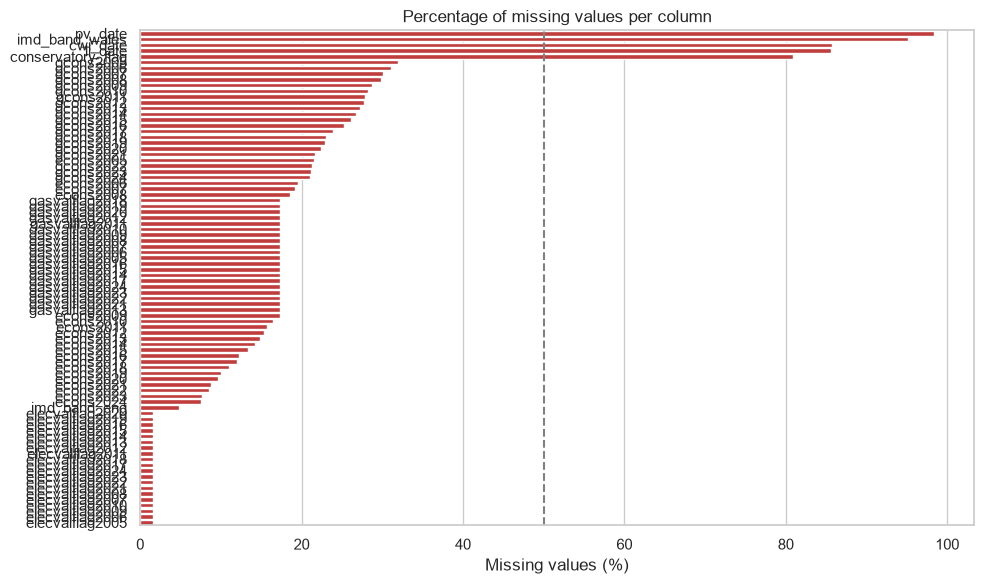

In [24]:
fig, ax = plt.subplots(figsize=(10, 6))

# Only plot the columns that have at least one missing value
missing_to_plot = missing[missing["pct_missing"] > 0]

sns.barplot(data=missing_to_plot, x="pct_missing", y=missing_to_plot.index, color="tab:red", ax=ax)
ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
ax.set_title("Percentage of missing values per column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
save_fig("01_missing_values")
plt.show()